<a href="https://colab.research.google.com/github/ikuto1910-jp/california-housing-analysis/blob/main/california_housing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 環境準備とライブラリのインポート
分析・可視化・モデリングに必要なライブラリを一括で読み込みます。

In [58]:
# 日本語フォントのインストール（-q で出力ログを非表示）
!pip install -q japanize_matplotlib

# 1. 警告の制御
import warnings
warnings.filterwarnings('ignore')

# 2. データ処理・数値計算
import numpy as np
import pandas as pd

# 3. データの可視化
import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib

# 4. 機械学習（モデル、前処理、交差検証、評価指標）
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score
import lightgbm as lgb

# 2. データの読み込みと探索的データ分析 (EDA)
カリフォルニア住宅価格データ（20,640件）を読み込み、目的変数（住宅価格）の分布と各特徴量との相関関係を確認します。

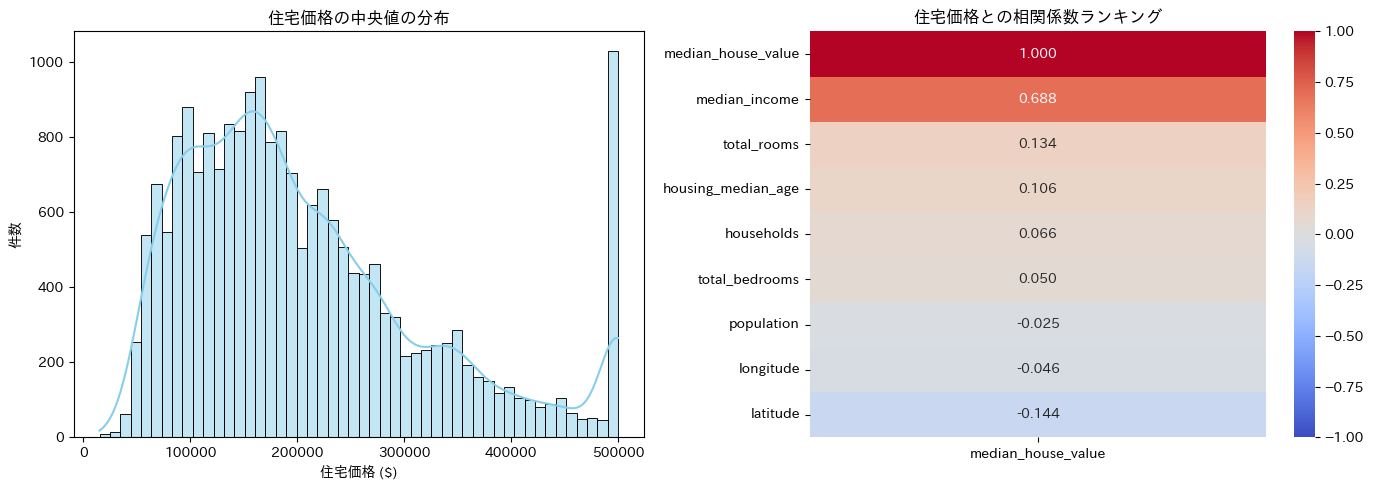

In [59]:
# データの読み込み
csv_url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df_housing = pd.read_csv(csv_url)

# 住宅価格の分布と、各特徴量との相関関係を可視化
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ① 目的変数のヒストグラム
sns.histplot(df_housing["median_house_value"], bins=50, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("住宅価格の中央値の分布", fontsize=12, weight="bold")
axes[0].set_xlabel("住宅価格 ($)")
axes[0].set_ylabel("件数")

# ② 相関行列のヒートマップ
numeric_cols = df_housing.select_dtypes(include=[np.number]).columns
price_corr = df_housing[numeric_cols].corr()[["median_house_value"]].sort_values(
    by="median_house_value", ascending=False
)

sns.heatmap(price_corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("住宅価格との相関係数ランキング", fontsize=12, weight="bold")

plt.tight_layout()
plt.show()

# 3. 前処理と特徴量エンジニアリング
欠損値（`total_bedrooms`）の中央値補完、ドメイン知識に基づく3つの比率特徴量の生成、およびカテゴリ変数（`ocean_proximity`）のOne-Hotエンコーディングを行います。

In [60]:
df_clean = df_housing.copy()

# 1. 欠損値の補完（中央値）
bedroom_median = df_clean["total_bedrooms"].median()
df_clean["total_bedrooms"] = df_clean["total_bedrooms"].fillna(bedroom_median)

# 2. ドメイン知識に基づく新特徴量の作成
df_clean["rooms_per_household"] = df_clean["total_rooms"] / df_clean["households"]
df_clean["bedrooms_per_room"] = df_clean["total_bedrooms"] / df_clean["total_rooms"]
df_clean["population_per_household"] = df_clean["population"] / df_clean["households"]

# 3. カテゴリ変数のダミー変数化（多重共線性対策として drop_first=True）
df_encoded = pd.get_dummies(df_clean, columns=["ocean_proximity"], drop_first=True, dtype=int)

# 4. 説明変数(X)と目的変数(y)の分離
X = df_encoded.drop(columns=["median_house_value"])
y = df_encoded["median_house_value"]

print(f"前処理後の特徴量数: {X.shape[1]} 列 / データ件数: {len(X):,} 件")

前処理後の特徴量数: 15 列 / データ件数: 20,640 件


# 4. 検証パイプラインの構築と線形モデルの評価
データリークを防ぐためのFold内標準化を組み込んだ交差検証関数を定義し、まずは3つの線形モデル（通常・Ridge・Lasso）の精度を比較します。

In [61]:
def evaluate_models_cv(models, X, y, n_splits=5, random_state=42):
    """データリークを防ぐFold内標準化を組み込んだ交差検証を実行し、指定されたモデルを評価する。

    Parameters
    ----------
    models : dict
        評価するモデルを格納した辞書 (key: モデル名, value: モデルオブジェクト)
    X : pandas.DataFrame
        説明変数（特徴量）のデータフレーム
    y : pandas.Series
        目的変数（住宅価格）のデータ
    n_splits : int, default 5
        交差検証の分割数 (K-FoldのK)
    random_state : int, default 42
        データのシャッフル時に使用する乱数シード

    Returns
    -------
    performance_df : pandas.DataFrame
        各モデルの「平均MAE」と「全体R²」をまとめた性能比較表
    oof_preds : dict
        各モデルのOOF予測値（NumPy配列）を格納した辞書 (key: モデル名, value: 予測値配列)
    """
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    oof_preds = {name: np.zeros(len(X)) for name in models.keys()}
    mae_scores = {name: [] for name in models.keys()}

    for train_idx, test_idx in kf.split(X):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # Fold内でのみ標準化を学習
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        for name, model in models.items():
            model.fit(X_train_scaled, y_train)
            preds = model.predict(X_test_scaled)
            oof_preds[name][test_idx] = preds
            mae_scores[name].append(mean_absolute_error(y_test, preds))

    results = []
    for name in models.keys():
        results.append({
            "モデル": name,
            "平均 MAE ($)": f"${np.mean(mae_scores[name]):,.2f}",
            "全体 R²": np.round(r2_score(y, oof_preds[name]), 4)
        })

    return pd.DataFrame(results), oof_preds

# 1. まずは線形モデル3つを定義して関数に渡す
linear_models = {
    "線形回帰（通常）": LinearRegression(),
    "Ridge回帰 (α=100)": Ridge(alpha=100.0),
    "Lasso回帰 (α=100)": Lasso(alpha=100.0, random_state=42)
}

linear_perf_df, linear_oof_preds = evaluate_models_cv(linear_models, X, y)

print("【線形モデルの性能比較（5-Fold CV）】")
display(linear_perf_df)

【線形モデルの性能比較（5-Fold CV）】


,モデル,平均 MAE ($),全体 R²
0,線形回帰（通常）,"$49,574.43",0.6414
1,Ridge回帰 (α=100),"$49,554.62",0.6416
2,Lasso回帰 (α=100),"$49,551.84",0.6419


# 5. 線形モデルの特徴量係数の比較
線形モデルごとの標準化係数を取得し、Seabornの棒グラフで住宅価格への影響度を視覚化します。

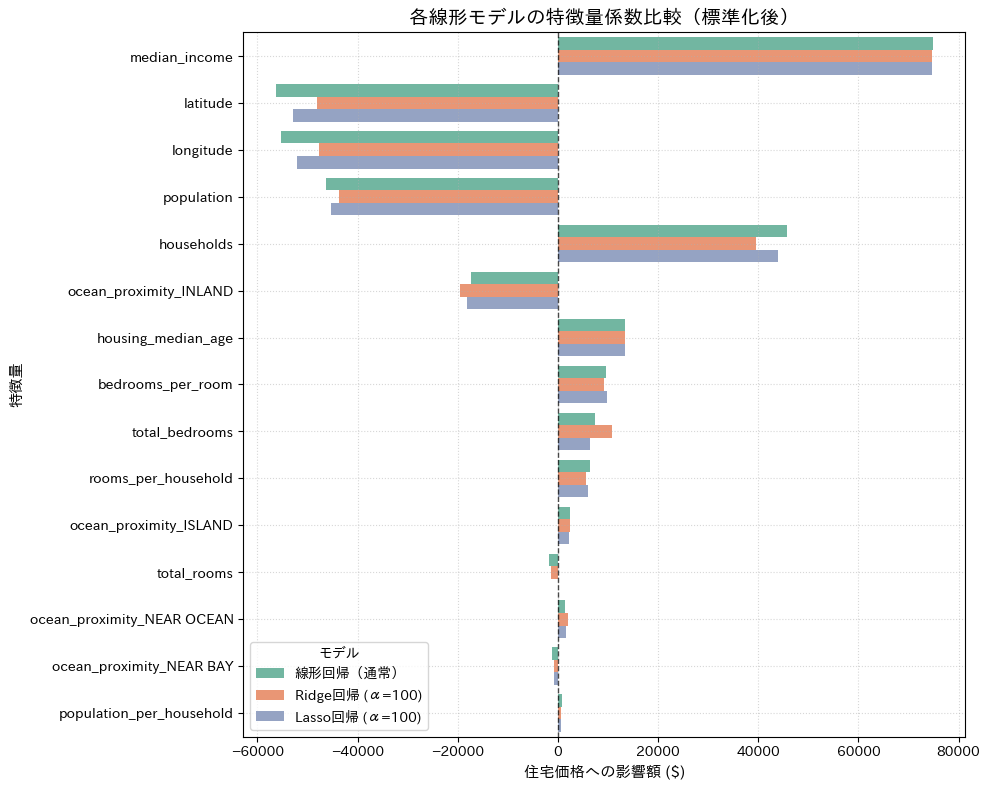

In [62]:
# 全データを用いた標準化
scaler_all = StandardScaler()
X_scaled_all = scaler_all.fit_transform(X)

# 線形モデル3つで全データを学習し、係数（coef_）を取得
coef_data = {"特徴量": X.columns}
for name, model in linear_models.items():
    model.fit(X_scaled_all, y)
    coef_data[name] = np.round(model.coef_, 2)

coef_df = pd.DataFrame(coef_data)

# 線形回帰の係数の絶対値が大きい順に並び替え
coef_df["abs_lr"] = coef_df["線形回帰（通常）"].abs()
coef_df = coef_df.sort_values(by="abs_lr", ascending=False).drop(columns=["abs_lr"])

# Seaborn用にデータを縦持ちに変換して描画
df_plot = coef_df.melt(id_vars="特徴量", var_name="モデル", value_name="係数 ($)")

plt.figure(figsize=(10, 8))
sns.barplot(data=df_plot, x="係数 ($)", y="特徴量", hue="モデル", palette="Set2")

plt.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.7)
plt.title("各線形モデルの特徴量係数比較（標準化後）", fontsize=14, weight="bold")
plt.xlabel("住宅価格への影響額 ($)", fontsize=11)
plt.ylabel("特徴量", fontsize=11)
plt.grid(True, linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()

# 6. 非線形モデル（LightGBM）の実装とモデル解釈
## 6-1. LightGBMによる精度改善の検証
正則化を行っても線形モデルでは $R^2 \approx 0.64$ が限界であったため、非線形な関係を捉えられる勾配ブースティング決定木（LightGBM）を導入します。
ブロック3で定義した `evaluate_models_cv` 関数を再利用して同一条件で評価し、線形モデルと精度を比較します。

In [63]:
# LightGBMを定義
lgb_models = {
    "LightGBM (決定木)": lgb.LGBMRegressor(
        n_estimators=200, learning_rate=0.05, random_state=42, verbose=-1
    )
}

# ★ ブロック3で作った関数を再利用して1行で交差検証を実行！
lgb_perf_df, lgb_oof_preds = evaluate_models_cv(lgb_models, X, y)

# 線形モデルの成績表とLightGBMの成績表を結合して表示
final_performance_df = pd.concat([linear_perf_df, lgb_perf_df], ignore_index=True)

print("【全モデル性能比較（線形モデル vs 非線形モデル）】")
display(final_performance_df)

【全モデル性能比較（線形モデル vs 非線形モデル）】


,モデル,平均 MAE ($),全体 R²
0,線形回帰（通常）,"$49,574.43",0.6414
1,Ridge回帰 (α=100),"$49,554.62",0.6416
2,Lasso回帰 (α=100),"$49,551.84",0.6419
3,LightGBM (決定木),"$30,533.14",0.8421


## 6-2. 実測値 vs 予測値の散布図比較（Ceiling Effectの確認）
4つのモデルのOOF予測値を実測値と比較します。
実測値が $500,000 付近でプロットが垂直に並ぶ「上限打ち切り（Ceiling Effect）」が確認できます。
また、LightGBMではプロットが理想線（赤点線）の周囲に密集し、大幅に予測誤差が減少していることが視覚的にも確認できます。

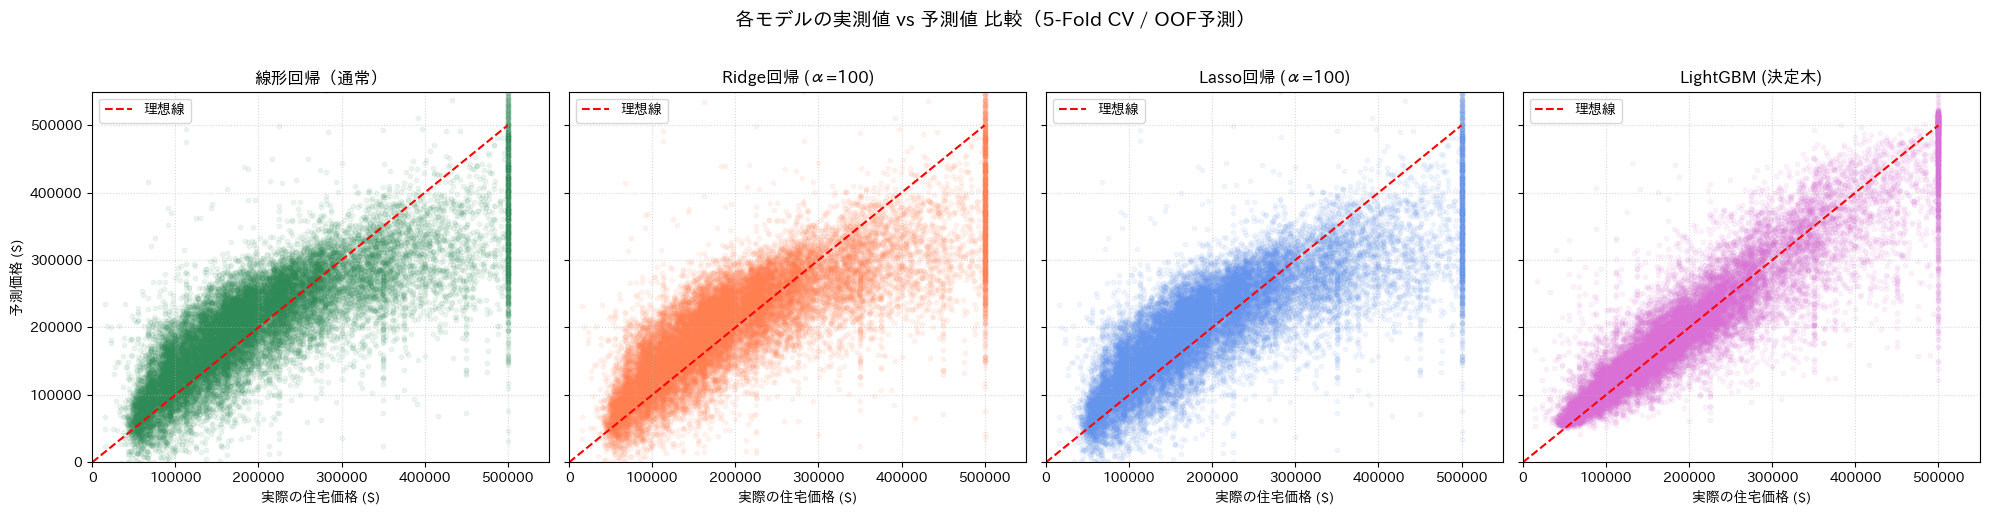

In [67]:
# 4つのグラフの枠を作成
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# 線形モデル3つとLightGBMの予測値をリストにまとめる
plot_models = [
    ("線形回帰（通常）", linear_oof_preds["線形回帰（通常）"], "seagreen"),
    ("Ridge回帰 (α=100)", linear_oof_preds["Ridge回帰 (α=100)"], "coral"),
    ("Lasso回帰 (α=100)", linear_oof_preds["Lasso回帰 (α=100)"], "cornflowerblue"),
    ("LightGBM (決定木)", lgb_oof_preds["LightGBM (決定木)"], "orchid"),
]

# 4つのモデルすべての散布図を一括描画
for i, (title, preds, color) in enumerate(plot_models):
    ax = axes[i]
    ax.scatter(y, preds, alpha=0.08, color=color, s=10)
    ax.plot([0, 500000], [0, 500000], color="red", linestyle="--", label="理想線")

    ax.set_xlim(0, 550000)
    ax.set_ylim(0, 550000)
    ax.set_title(title, fontsize=12, weight="bold")
    ax.set_xlabel("実際の住宅価格 ($)", fontsize=10)
    if i == 0:
        ax.set_ylabel("予測価格 ($)", fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)
    ax.legend(loc="upper left")

plt.suptitle(
    "各モデルの実測値 vs 予測値 比較（5-Fold CV / OOF予測）",
    fontsize=14,
    weight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

## 6-3. 特徴量重要度（Feature Importance）のバイアス補正
デフォルトの分岐回数（Split）では、値の種類が多い連続変数（緯度・経度）が見かけ上高く評価されるバイアス（High Cardinality Bias）が生じます。
純粋な予測誤差の削減量（Gain）で評価し直すことで、ドメイン知識通り「収入（median_income）」が最も価格決定に寄与していることを証明します。

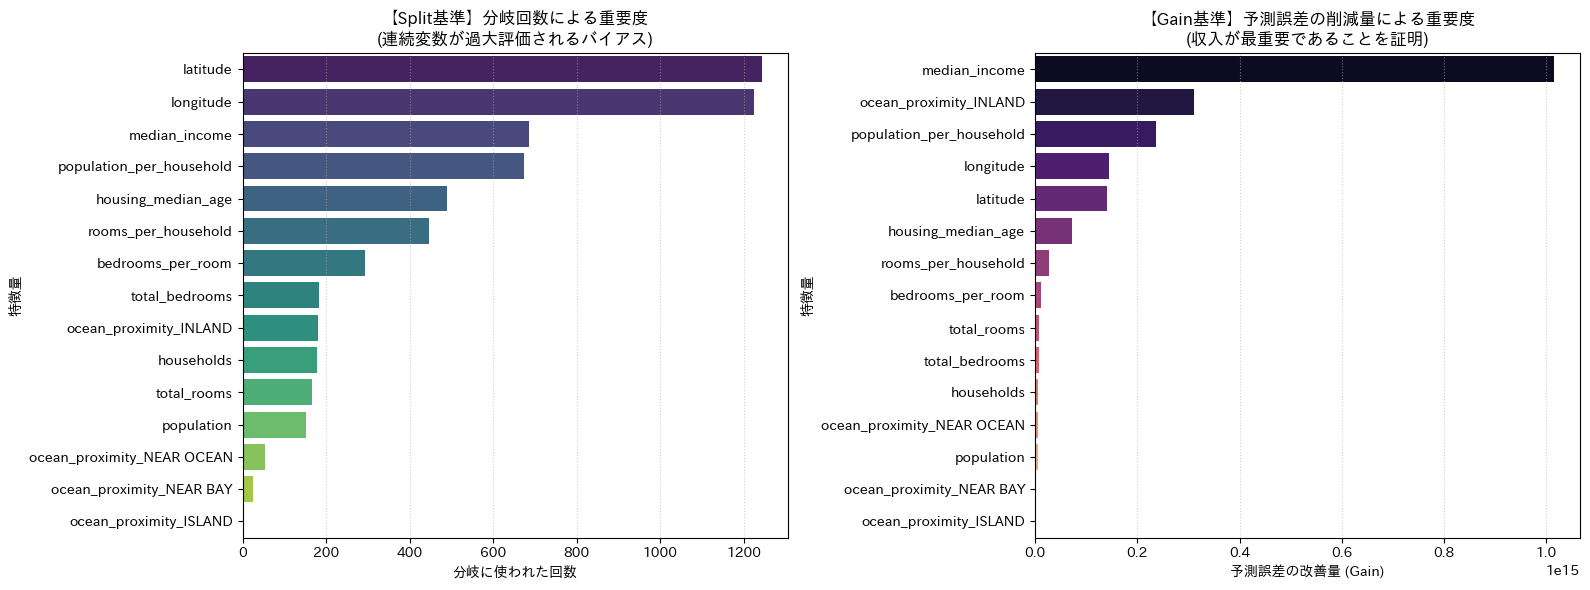

【LightGBM 変数重要度 (Gain) トップ5】


,特徴量,Split (分岐回数),Gain (貢献度)
0,median_income,687,1.015099e+15
1,ocean_proximity_INLAND,181,3.109348e+14
2,population_per_household,674,2.368829e+14
3,longitude,1225,1.453502e+14
4,latitude,1243,1.402939e+14


In [65]:
# 6-1で学習済みのLightGBMモデルを取り出す
lgb_model = lgb_models["LightGBM (決定木)"]

# 重要度の取得 (Split: 分岐回数, Gain: 誤差削減量)
split_imp = lgb_model.booster_.feature_importance(importance_type="split")
gain_imp = lgb_model.booster_.feature_importance(importance_type="gain")

df_imp = pd.DataFrame(
    {"特徴量": X.columns, "Split (分岐回数)": split_imp, "Gain (貢献度)": gain_imp}
)

# 2つのグラフを横並びで描画
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ① Split基準（バイアスあり）
df_imp_split = df_imp.sort_values(by="Split (分岐回数)", ascending=False).reset_index(drop=True)
sns.barplot(data=df_imp_split, x="Split (分岐回数)", y="特徴量", hue="特徴量", palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("【Split基準】分岐回数による重要度\n(連続変数が過大評価されるバイアス)", fontsize=12, weight="bold")
axes[0].set_xlabel("分岐に使われた回数", fontsize=10)
axes[0].grid(axis="x", linestyle=":", alpha=0.6)

# ② Gain基準（真の貢献度・ドメイン知識と整合）
df_imp_gain = df_imp.sort_values(by="Gain (貢献度)", ascending=False).reset_index(drop=True)
sns.barplot(data=df_imp_gain, x="Gain (貢献度)", y="特徴量", hue="特徴量", palette="magma", legend=False, ax=axes[1])
axes[1].set_title("【Gain基準】予測誤差の削減量による重要度\n(収入が最重要であることを証明)", fontsize=12, weight="bold")
axes[1].set_xlabel("予測誤差の改善量 (Gain)", fontsize=10)
axes[1].grid(axis="x", linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

print("【LightGBM 変数重要度 (Gain) トップ5】")
display(df_imp_gain.head(5))